# Dimensionality Reduction with PCA

## Learning objectives
- Standardize features before PCA when scales differ.
- Inspect explained variance.
- Reduce data to two principal components.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

data = load_wine(as_frame=True)
X, y = data.data, data.target
print("Original shape:", X.shape)
X.head()

Original shape: (178, 13)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


In [2]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## 1. Explained variance

In [3]:
pca_full = PCA()
pca_full.fit(X_train_scaled)
variance = pd.DataFrame({"Component": range(1, len(pca_full.explained_variance_ratio_)+1), "Explained variance": pca_full.explained_variance_ratio_, "Cumulative variance": pca_full.explained_variance_ratio_.cumsum()})
variance

,Component,Explained variance,Cumulative variance
0,1,0.357921,0.357921
1,2,0.192707,0.550628
2,3,0.110198,0.660826
3,4,0.072723,0.733549
4,5,0.067219,0.800768
5,6,0.051319,0.852087
6,7,0.043774,0.895862
7,8,0.025009,0.920870
8,9,0.022794,0.943665
9,10,0.018771,0.962436


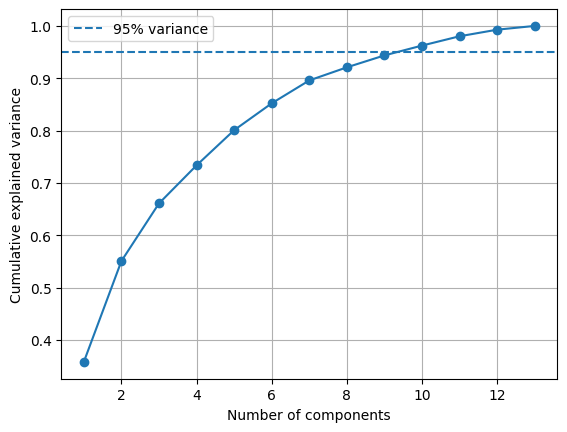

In [4]:
plt.plot(variance["Component"], variance["Cumulative variance"], marker="o")
plt.axhline(0.95, linestyle="--", label="95% variance")
plt.xlabel("Number of components"); plt.ylabel("Cumulative explained variance"); plt.legend(); plt.grid(True); plt.show()

## 2. Transform to two components

In [5]:
pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)
print("Original:", X_train.shape, "Reduced:", X_train_pca.shape)
print("Variance ratios:", pca.explained_variance_ratio_.round(3))
print("Total variance explained:", round(pca.explained_variance_ratio_.sum(), 3))

Original: (142, 13) Reduced: (142, 2)
Variance ratios: [0.358 0.193]
Total variance explained: 0.551


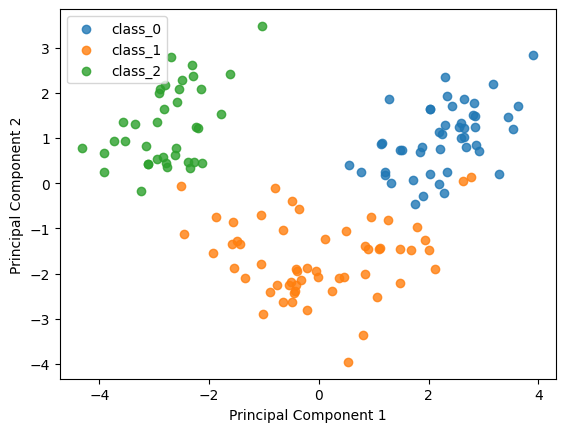

In [6]:
plot_df = pd.DataFrame(X_train_pca, columns=["PC1", "PC2"])
plot_df["Class"] = y_train.to_numpy()
for class_id in sorted(plot_df["Class"].unique()):
    part = plot_df[plot_df["Class"] == class_id]
    plt.scatter(part["PC1"], part["PC2"], label=data.target_names[class_id], alpha=.8)
plt.xlabel("Principal Component 1"); plt.ylabel("Principal Component 2"); plt.legend(); plt.show()

## Key takeaways
- PCA creates new component axes ordered by explained variance.
- Scale features before PCA when they use different units.
- Fit PCA on training data, then transform test data with the same fitted object.
- Reduced dimensions may discard information.